## 1. Environment Setup

Import the libraries required for dataset inspection, visualization,
file handling, and preprocessing verification.

In [1]:
from pathlib import Path
import sys
import hashlib
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

### Google Drive Connection

Connect Google Drive to access the preprocessed HUSTmotor dataset.
If Drive is already mounted, reuse the existing connection.

In [2]:
DRIVE_ROOT = Path("/content/drive/MyDrive")

if DRIVE_ROOT.is_dir():
    print("Google Drive is already accessible.")
else:
    drive.mount("/content/drive")

assert DRIVE_ROOT.is_dir(), "Google Drive is not accessible."
print("Google Drive:", DRIVE_ROOT)

Mounted at /content/drive
Google Drive: /content/drive/MyDrive


### Dataset Configuration

Locate the preprocessed HUSTmotor dataset in Google Drive.

The window size is configurable so that future preprocessing
versions can be explored without rewriting the notebook.

In [3]:
PROJECT_DIR = DRIVE_ROOT / "ISCF_Project"
WINDOW_SIZE = 1024
DATA_FILENAME = f"hustmotor_{WINDOW_SIZE}.npz"
DATA_PATH = PROJECT_DIR / "data" / DATA_FILENAME

if not DATA_PATH.is_file():
    matches = list(DRIVE_ROOT.rglob(DATA_FILENAME))

    if len(matches) == 1:
        DATA_PATH = matches[0]
    elif len(matches) > 1:
        raise RuntimeError(
            f"Multiple datasets found: {matches}. "
            "Select the intended version explicitly."
        )
    else:
        raise FileNotFoundError(
            f"Could not find {DATA_FILENAME} in Google Drive."
        )

print("Selected dataset:", DATA_PATH)
print("Window size:", WINDOW_SIZE)

Selected dataset: /content/drive/MyDrive/ISCF_Project/data/hustmotor_1024.npz
Window size: 1024


## 2. Preprocessing Repository

Access preprocessing implementation and import the
domain-generalization task loader.

The repository is cloned only when it is not already available
in the current Colab environment.

In [4]:
REPO_DIR = Path("/content/ISCF_Project")

if not (REPO_DIR / "preprocess_hustmotor.py").is_file():
    if REPO_DIR.exists():
        raise RuntimeError(
            "Repository folder exists but the preprocessing file is missing."
        )

    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Genti24-bit/ISCF_Project.git",
            str(REPO_DIR)
        ],
        check=True
    )

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from preprocess_hustmotor import load_dg_task
print("Preprocessing loader imported successfully!")

Preprocessing loader imported successfully!


### Dataset Integrity Verification

Calculate the SHA-256 checksum to identify the exact dataset
version used in the experiment.

For the original 1024-point dataset, compare the checksum
against the previously recorded reference value.

In [5]:
REFERENCE_SHA256 = {
    "hustmotor_1024.npz":
        "bd4e3c7273fa5efced76a39863e7a7f80255b8e382383519d613492cf671c658"
}

sha256 = hashlib.sha256()

with open(DATA_PATH, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        sha256.update(chunk)

actual_hash = sha256.hexdigest()

expected_hash = REFERENCE_SHA256.get(DATA_PATH.name)

print("Dataset:", DATA_PATH.name)
print("SHA-256:", actual_hash)

if expected_hash is not None:
    checksum_matches = actual_hash == expected_hash
    print("Reference checksum matches:", checksum_matches)

    if not checksum_matches:
        print("WARNING: Dataset differs from the recorded version.")
else:
    print("No reference checksum registered for this dataset.")

Dataset: hustmotor_1024.npz
SHA-256: bd4e3c7273fa5efced76a39863e7a7f80255b8e382383519d613492cf671c658
Reference checksum matches: True


## 3. Domain-Generalization Task

Load the vibration signals and their corresponding fault labels using the predefined domain-generalization splits.

For the currently selected Task 9, the 5 Hz operating condition is held out for testing,
while the 10, 20, and 30 Hz conditions are used for training and validation.

In [6]:
TARGET_DOMAIN = 0
TASK_ID = TARGET_DOMAIN + 9

task = load_dg_task(
    str(DATA_PATH),
    target_domain=TARGET_DOMAIN
)

Xv_train, y_train = task["train"][0], task["train"][2]
Xv_val, y_val = task["val"][0], task["val"][2]
Xv_test, y_test = task["target"][0], task["target"][2]

print(f"Task {TASK_ID}")
print("Target domain:", TARGET_DOMAIN)

print("\nVibration signals:")
print("Training:", Xv_train.shape)
print("Validation:", Xv_val.shape)
print("Testing:", Xv_test.shape)

print("\nLabels:")
print("Training:", y_train.shape)
print("Validation:", y_val.shape)
print("Testing:", y_test.shape)

Task 9
Target domain: 0

Vibration signals:
Training: (14400, 1024)
Validation: (3600, 1024)
Testing: (1200, 1024)

Labels:
Training: (14400,)
Validation: (3600,)
Testing: (1200,)


## 4. Vibration Dataset Exploration

### 4.1. Signal Dimensions

Check the dimensions of the vibration signals and verify that the number of samples matches the number of labels in each dataset split.

In [10]:
splits = {
    "Training": (Xv_train, y_train),
    "Validation": (Xv_val, y_val),
    "Testing": (Xv_test, y_test)
}

for name, (X, y) in splits.items():
    print(f"\n{name} set:")
    print("Signal shape:", X.shape)
    print("Labels shape:", y.shape)

    assert X.ndim == 2, f"{name}: Expected 2D signals"
    print("Window size:", X.shape[1])
    assert len(X) == len(y), f"{name}: Samples and labels do not match"
    assert np.isfinite(X).all(), f"{name}: Invalid signal values found"

print("\nAll vibration dataset checks passed!")


Training set:
Signal shape: (14400, 1024)
Labels shape: (14400,)
Window size: 1024

Validation set:
Signal shape: (3600, 1024)
Labels shape: (3600,)
Window size: 1024

Testing set:
Signal shape: (1200, 1024)
Labels shape: (1200,)
Window size: 1024

All vibration dataset checks passed!


### 4.2. Fault Class Distribution

Examine the number of vibration samples belonging to each motor condition in the training, validation, and test sets to verify that all fault classes are represented.

In [11]:
with np.load(DATA_PATH, allow_pickle=False) as data:
    class_names = [str(c) for c in data["classes"]]

class_distribution = pd.DataFrame({
    "Class": class_names,
    "Training": np.bincount(y_train, minlength=len(class_names)),
    "Validation": np.bincount(y_val, minlength=len(class_names)),
    "Testing": np.bincount(y_test, minlength=len(class_names))
})

display(class_distribution)

,Class,Training,Validation,Testing
0,H,2400,600,200
1,BF,2400,600,200
2,BOW,2400,600,200
3,BROKEN,2400,600,200
4,MISAL,2400,600,200
5,UNBAL,2400,600,200


### 4.3. Class Distribution Visualization

Visualize the distribution of vibration samples across the six motor conditions in the training, validation, and test sets to check whether the classes are balanced.

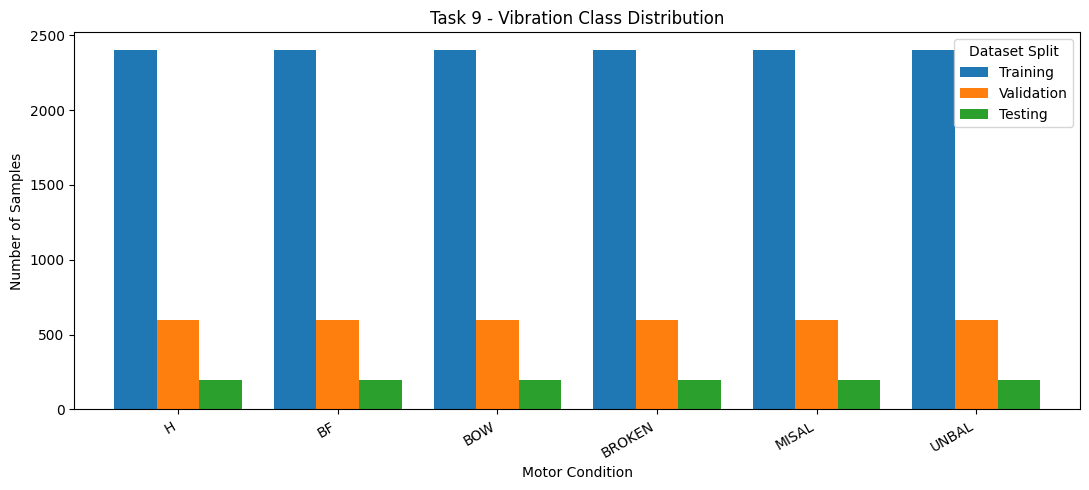

In [12]:
class_distribution.set_index("Class").plot(
    kind="bar",
    figsize=(11, 5),
    width=0.8
)

plt.title(f"Task {TASK_ID} - Vibration Class Distribution")
plt.xlabel("Motor Condition")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

### 4.4. Operating Domain Distribution

Check the number of vibration samples recorded at each operating speed and verify the distribution across the four domains.

,Domain,Samples
0,B1_5Hz,6000
1,B2_10Hz,6000
2,B3_20Hz,6000
3,B4_30Hz,6000


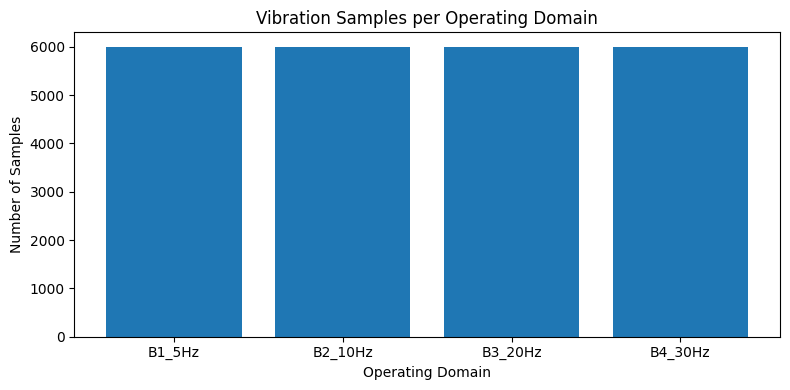

In [13]:
with np.load(DATA_PATH, allow_pickle=False) as data:
    domains = data["domain"]
    domain_names = data["domains"]

domain_counts = pd.DataFrame({
    "Domain": domain_names,
    "Samples": np.bincount(domains, minlength=len(domain_names))
})

display(domain_counts)

plt.figure(figsize=(8, 4))
plt.bar(domain_counts["Domain"], domain_counts["Samples"])
plt.title("Vibration Samples per Operating Domain")
plt.xlabel("Operating Domain")
plt.ylabel("Number of Samples")
plt.tight_layout()
plt.show()

### 4.5. Signal Normalization Verification

Calculate the mean and standard deviation of each vibration window to verify that the preprocessing produced approximately zero-mean, unit-variance signals.

In [14]:
for name, (X, y) in splits.items():

    window_means = X.mean(axis=1)
    window_stds = X.std(axis=1)

    print(f"\n{name}:")
    print("Mean absolute window mean:",
          np.mean(np.abs(window_means)))
    print("Average window standard deviation:",
          np.mean(window_stds))

    print("Minimum window std:", window_stds.min())
    print("Maximum window std:", window_stds.max())

    assert np.allclose(window_means, 0, atol=1e-4)
    assert np.allclose(window_stds, 1, atol=1e-3)

print("\nNormalization checks passed!")


Training:
Mean absolute window mean: 5.4112252e-08
Average window standard deviation: 1.0
Minimum window std: 0.9999998
Maximum window std: 1.0000001

Validation:
Mean absolute window mean: 5.2849906e-08
Average window standard deviation: 1.0
Minimum window std: 0.9999998
Maximum window std: 1.0000001

Testing:
Mean absolute window mean: 2.543239e-07
Average window standard deviation: 1.0
Minimum window std: 0.9999999
Maximum window std: 1.0000001

Normalization checks passed!


### 4.6. Duplicate Signal Verification

Check whether identical vibration windows appear in different dataset splits. This helps identify potential data leakage caused by duplicated samples.

In [15]:
def get_signal_hashes(X):
    return {
        hashlib.sha256(np.ascontiguousarray(row).tobytes()).hexdigest()
        for row in X
    }

train_hashes = get_signal_hashes(Xv_train)
val_hashes = get_signal_hashes(Xv_val)
test_hashes = get_signal_hashes(Xv_test)

print("Training / Validation duplicates:",
      len(train_hashes & val_hashes))

print("Training / Testing duplicates:",
      len(train_hashes & test_hashes))

print("Validation / Testing duplicates:",
      len(val_hashes & test_hashes))

Training / Validation duplicates: 0
Training / Testing duplicates: 0
Validation / Testing duplicates: 0


### 4.7. Vibration Signal Visualization

Plot representative vibration windows from each fault class to examine differences in signal amplitude and waveform patterns.

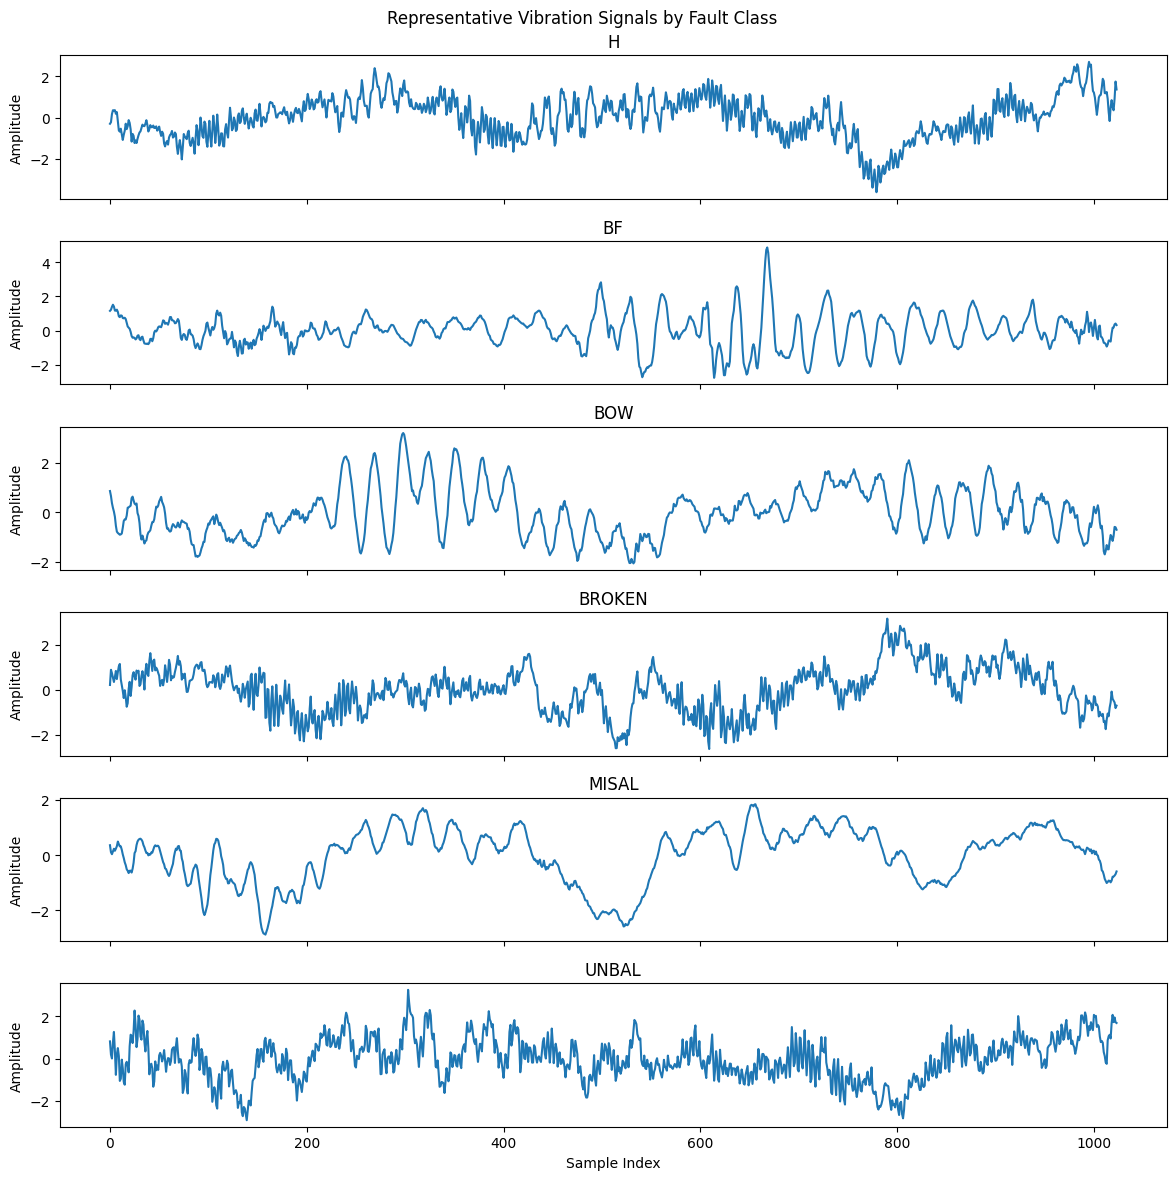

In [16]:
fig, axes = plt.subplots(
    len(class_names), 1,
    figsize=(12, 12),
    sharex=True
)

for class_id, ax in enumerate(axes):

    indices = np.where(y_train == class_id)[0]

    if len(indices) == 0:
        ax.set_title(f"{class_names[class_id]} - No samples")
        continue

    signal = Xv_train[indices[0]]

    ax.plot(signal)
    ax.set_title(class_names[class_id])
    ax.set_ylabel("Amplitude")

axes[-1].set_xlabel("Sample Index")

plt.suptitle("Representative Vibration Signals by Fault Class")
plt.tight_layout()
plt.show()

**Interpretation:**

The figure shows one representative vibration signal for each of the six motor conditions (H, BF, BOW, BROKEN, MISAL, and UNBAL), using 1024-point windows from the training set.

The signals show different vibration patterns. BF and BOW exhibit more noticeable oscillations and amplitude peaks, while H, BROKEN, MISAL, and UNBAL show more irregular variations throughout the window. These differences suggest that vibration signals contain useful features for distinguishing motor conditions.

Since the signals are normalized, the amplitudes represent relative variations rather than original physical measurements. Also, each plot represents only one sample per class, so these observations cannot be generalized to all samples without further analysis.

## 5. Domain-Generalization Split Verification

Verify that Tasks 9–12 follow the intended domain-generalization protocol by comparing the vibration signals and labels returned by the preprocessing loader with the expected partitions reconstructed from the dataset metadata.

This check ensures that the training, validation, and test sets contain the correct samples based on their operating domains and acquisition blocks.

In [20]:
# Load vibration data and metadata
with np.load(DATA_PATH, allow_pickle=False) as data:
    all_domains = data["domain"]
    all_blocks = data["block"]
    all_vibration = data["vib"]
    all_labels = data["y"]
    domain_names = data["domains"]

results = []

# Verify all four domain-generalization tasks
for target_domain in range(len(domain_names)):

    task_id = target_domain + 9

    task_data = load_dg_task(
        str(DATA_PATH),
        target_domain=target_domain
    )

    # Define source domains (excluding the target domain)
    source_domains = [
        d for d in np.unique(all_domains)
        if d != target_domain
    ]

    # Reconstruct the expected splits using domain and block metadata
    masks = {
        "train": (
            np.isin(all_domains, source_domains)
            & np.isin(all_blocks, [0, 1, 2, 3])
        ),
        "val": (
            np.isin(all_domains, source_domains)
            & (all_blocks == 4)
        ),
        "target": (
            (all_domains == target_domain)
            & (all_blocks == 4)
        )
    }

    # Compare loader outputs with the expected vibration samples and labels
    for split_name, mask in masks.items():

        X = task_data[split_name][0]
        y = task_data[split_name][2]

        assert np.array_equal(X, all_vibration[mask]), (
            f"Task {task_id}: {split_name} vibration signals mismatch"
        )

        assert np.array_equal(y, all_labels[mask]), (
            f"Task {task_id}: {split_name} labels mismatch"
        )

    results.append({
        "Task": task_id,
        "Target Domain": domain_names[target_domain],
        "Training": len(task_data["train"][0]),
        "Validation": len(task_data["val"][0]),
        "Testing": len(task_data["target"][0]),
        "Status": "Passed"
    })

results_df = pd.DataFrame(results)

display(results_df)

print("\nAll four domain-generalization tasks verified!")

,Task,Target Domain,Training,Validation,Testing,Status
0,9,B1_5Hz,14400,3600,1200,Passed
1,10,B2_10Hz,14400,3600,1200,Passed
2,11,B3_20Hz,14400,3600,1200,Passed
3,12,B4_30Hz,14400,3600,1200,Passed



All four domain-generalization tasks verified!
